# 05 — Especificação do projeto e protocolo analítico

O exemplo de projeto do professor organiza pergunta, unidade, resposta, fatores e procedimento. Esta versão registra as escolhas efetivamente usadas na Entrega 2 e separa o desenho conceitual do status real dos dados.

## Objetivo operacional

Descrever e comparar o ΔGPA entre grupos STEM + Junior definidos por três fatores binários: modo primário de uso da IA, ansiedade em provas e horas tradicionais de estudo.

### Protocolo aplicado

| Elemento | Definição nesta análise |
|---|---|
| Fonte | `csv/ai_student_impact_dataset.csv` (50.000 linhas) |
| População de análise | Estudantes STEM no terceiro ano (`Junior`) |
| Unidade | Um estudante identificado por `Student_ID` |
| Resposta | `Post_Semester_GPA − Pre_Semester_GPA` |
| A | Passivo (+1) vs demais casos ativos (−1) |
| B | Ansiedade > mediana (+1) vs ≤ mediana (−1) |
| C | Estudo tradicional > mediana (+1) vs ≤ mediana (−1) |
| Análise principal | Modelo completo 2³ nos dados brutos; ANOVA tipo III com HC3 |
| Incerteza dos efeitos | IC95% bootstrap estratificado por célula |

## O que não foi feito

Não houve intervenção ou alocação aleatória de alunos, sequência de execução, controle experimental ou repetição computacional independente. Assim, “fatorial 2³” descreve a estrutura de contrastes, não um ensaio aleatorizado. Não igualamos os tamanhos por descarte; o bootstrap de réplicas ilustrativas da versão do script é apêndice e não deve fundamentar p-valores.

In [1]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

import sys
from pathlib import Path

_plot_dir = next(
    (
        candidate
        for parent in (Path.cwd(), *Path.cwd().parents)
        for candidate in (
            parent,
            parent / "notebooks_adaptados",
            parent / "entrega2" / "notebooks_adaptados",
        )
        if (candidate / "visualizacoes.py").is_file()
    ),
    None,
)
if _plot_dir is None:
    raise FileNotFoundError("Não encontrei visualizacoes.py junto aos notebooks adaptados.")
sys.path.insert(0, str(_plot_dir))

from visualizacoes import (
    configure_plots, plot_cell_counts, plot_factorial_cube,
    plot_protocol_flow, plot_quality_dashboard, save_figure,
)
from scipy import stats
from IPython.display import display

configure_plots()

DATA_NAME = "ai_student_impact_dataset.csv"
ROOT = next(
    (base for base in (Path.cwd(), *Path.cwd().parents)
     if (base / "csv" / DATA_NAME).is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        f"Não encontrei csv/{DATA_NAME} em nenhum diretório ancestral "
        f"do diretório atual: {Path.cwd()}"
    )
CSV_PATH = ROOT / "csv" / DATA_NAME
df = pd.read_csv(CSV_PATH)

required = {
    "Student_ID", "Major_Category", "Year_of_Study", "Pre_Semester_GPA",
    "Post_Semester_GPA", "Primary_Use_Case", "Anxiety_Level_During_Exams",
    "Traditional_Study_Hours",
}
missing_columns = required.difference(df.columns)
if missing_columns:
    raise ValueError(f"Colunas obrigatórias ausentes no CSV: {sorted(missing_columns)}")

df["Delta_GPA"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]
PASSIVE_USE_CASES = {"Copywriting/Drafting", "Direct_Answer_Generation"}
df["A"] = np.where(df["Primary_Use_Case"].isin(PASSIVE_USE_CASES), 1, -1)
stem_junior = df.loc[
    (df["Major_Category"] == "STEM") & (df["Year_of_Study"] == "Junior")
].copy()

ANXIETY_Q2 = stem_junior["Anxiety_Level_During_Exams"].median()
STUDY_Q2 = stem_junior["Traditional_Study_Hours"].median()
stem_junior["B"] = np.where(
    stem_junior["Anxiety_Level_During_Exams"] > ANXIETY_Q2, 1, -1
)
stem_junior["C"] = np.where(
    stem_junior["Traditional_Study_Hours"] > STUDY_Q2, 1, -1
)
factorial = stem_junior.copy()

YATES = ["(1)", "a", "b", "ab", "c", "ac", "bc", "abc"]
CELLS = [
    (a, b, c)
    for c in (-1, 1)
    for b in (-1, 1)
    for a in (-1, 1)
]
cell_number = {cell: number for number, cell in enumerate(CELLS, start=1)}
factorial["celula"] = [
    cell_number[(int(row.A), int(row.B), int(row.C))]
    for row in factorial[["A", "B", "C"]].itertuples(index=False)
]
groups = {
    key: frame["Delta_GPA"].to_numpy()
    for key, frame in factorial.groupby(["A", "B", "C"], sort=False)
}
cell_counts = factorial.groupby(["A", "B", "C"]).size()
if set(groups) != set(CELLS):
    raise ValueError("A classificação não produziu as oito células fatoriais.")
if factorial["Delta_GPA"].isna().any():
    raise ValueError("Há ΔGPA ausente; resolva os dados ausentes antes da análise.")

print(f"Arquivo: {CSV_PATH}")
print(f"Dataset completo: n={len(df):,}")
print(f"Recorte STEM + Junior: n={len(stem_junior):,}")
print(f"Analisados nas oito células: n={len(factorial):,}")
print(f"Cortes: ansiedade Q2={ANXIETY_Q2:g}; estudo Q2={STUDY_Q2:.2f} h")
print(f"Menor célula: n={cell_counts.min():,}")

configure_plots()


Arquivo: /home/wagner/pcc170/csv/ai_student_impact_dataset.csv
Dataset completo: n=50,000
Recorte STEM + Junior: n=3,279
Analisados nas oito células: n=3,279
Cortes: ansiedade Q2=4; estudo Q2=10.91 h
Menor célula: n=181


## Conferência do plano contra os dados preparados

In [2]:

protocol_check = pd.DataFrame([
    ("Base", len(df), "50.000 no dataset de referência"),
    ("Recorte STEM + Junior", len(stem_junior), "3.279"),
    ("Análise nas oito células", len(factorial), "3.279 pela regra principal"),
    ("Número de células não vazias", len(groups), "8"),
    ("Menor n por célula", int(cell_counts.min()), "181"),
    ("Maior n por célula", int(cell_counts.max()), "667"),
], columns=["item", "observado", "referência"])
display(protocol_check)
display(
    factorial.groupby(["A", "B", "C"]).size()
    .reindex(CELLS)
    .rename("n")
    .to_frame()
)


,item,observado,referência
0,Base,50000,50.000 no dataset de referência
1,Recorte STEM + Junior,3279,3.279
2,Análise nas oito células,3279,3.279 pela regra principal
3,Número de células não vazias,8,8
4,Menor n por célula,181,181
5,Maior n por célula,667,667


,,,n
A,B,C,
-1,-1,-1,667
1,-1,-1,210
-1,1,-1,576
1,1,-1,187
-1,-1,1,639
1,-1,1,235
-1,1,1,584
1,1,1,181


## Fluxo amostral e composição do desenho

O fluxo mostra a seleção realmente observada; a figura ao lado resume o tamanho das oito células.

findfont: Failed to find font weight semibold for DejaVu Sans, now using 700.


Figura salva: 05_fluxo_selecao.png (PNG) e 05_fluxo_selecao.pdf (PDF)


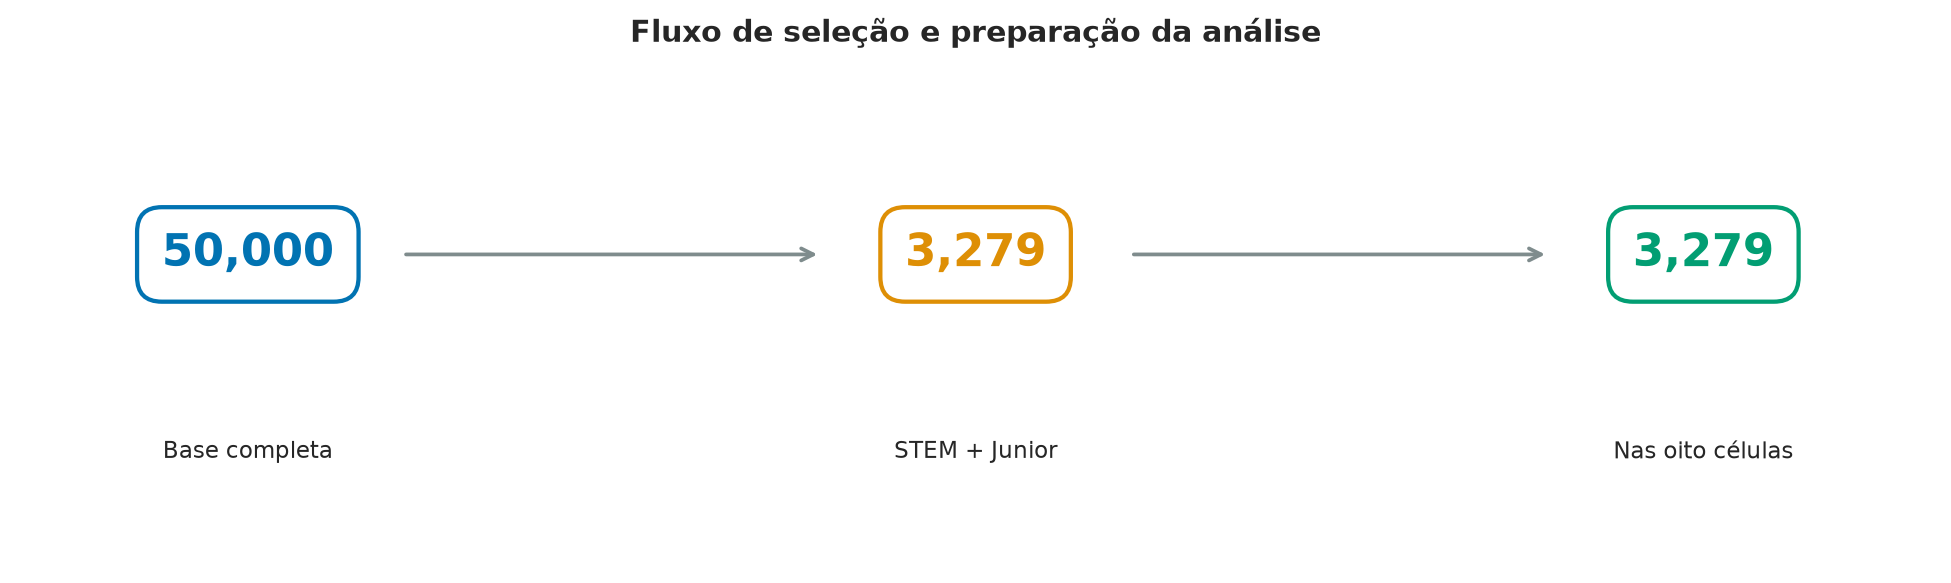

Figura salva: 05_composicao_celulas.png (PNG) e 05_composicao_celulas.pdf (PDF)


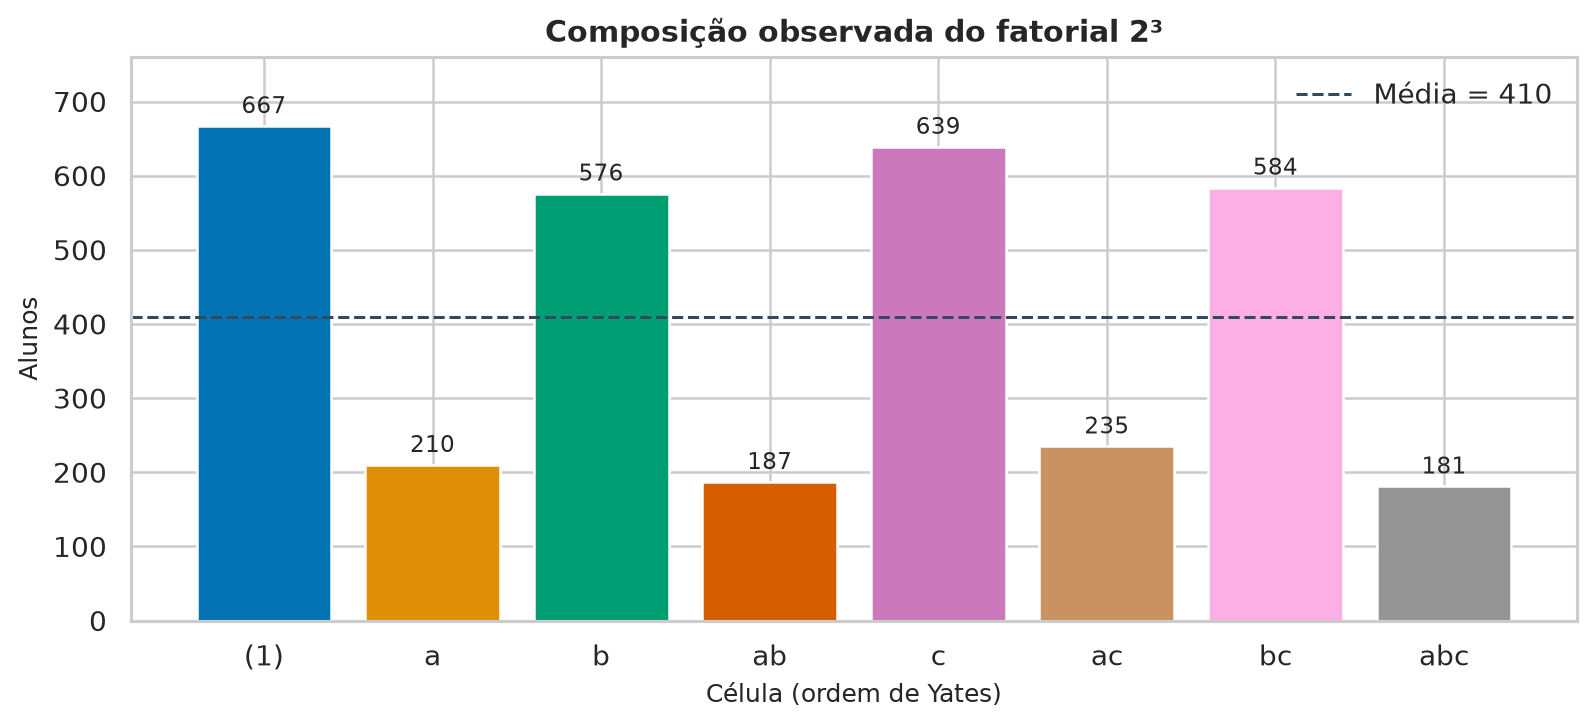

In [3]:
fig = plot_protocol_flow(
    [len(df), len(stem_junior), len(factorial)],
    ["Base completa", "STEM + Junior", "Nas oito células"],
)
save_figure(fig, "05_fluxo_selecao")

fig = plot_cell_counts(
    [len(groups[cell]) for cell in CELLS],
    YATES,
    title="Composição observada do fatorial 2³",
)
save_figure(fig, "05_composicao_celulas")


## Plano de análise e reprodutibilidade

1. Validar identificadores, campos críticos e limites do GPA.
2. Filtrar STEM + Junior; calcular ΔGPA; definir medianas e níveis ±1.
3. Descrever distribuição e tamanhos das oito células.
4. Ajustar `Delta_GPA ~ A * B * C` em todos os alunos elegíveis.
5. Reportar os contrastes e IC95% bootstrap; usar HC3 para testes robustos.
6. Examinar resíduos, heterocedasticidade, balanceamento prévio e sensibilidades.
7. Interpretar magnitude, incerteza, limitações observacionais e variância residual.

Para reproduzir os arquivos consolidados e figuras do projeto, executar `python pcc170_entrega02.py` a partir de `entrega2/`. A execução do script também é pré-requisito do notebook 07, que lê os CSVs de resultados.